In [ ]:
import zipfile

In [14]:
!pip install pandas numpy scikit-learn xgboost

In [15]:
import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [21]:
import zipfile

extract_dir = "emg_data_extracted"

zip_files = glob.glob("*.zip")

if not zip_files:
    print("ERROR: No .zip files found! Please check that your dataset zip file is uploaded.")
else:
    zip_filename = zip_files[0]
    print(f"Extracting '{zip_filename}' into '{extract_dir}/'...")

    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    print(f"Extraction completed successfully.")

Extracting 'emg+data+for+gestures.zip' into 'emg_data_extracted/'...
Extraction completed successfully.


In [22]:
def load_emg_data(base_folder="emg_data_extracted"):
    data_files = glob.glob(os.path.join(base_folder, "**", "*.txt"), recursive=True) + \
                 glob.glob(os.path.join(base_folder, "**", "*.csv"), recursive=True)

    if not data_files:
        raise FileNotFoundError(f"No data files (.txt or .csv) found inside '{base_folder}'.")

    print(f"Found {len(data_files)} data file(s). Processing...")
    data_frames = []

    for file in data_files:
        try:
            # First, read the file normally to check if it has a string header
            df_preview = pd.read_csv(file, header=None, nrows=2, sep=r'\s+|,', engine='python')

            # Determine if row 0 contains text headers
            has_header = False
            for val in df_preview.iloc[0]:
                if isinstance(val, str) and not val.replace('.', '', 1).isdigit():
                    has_header = True
                    break

            # Reload properly handling header presence
            skip = 1 if has_header else 0
            df = pd.read_csv(file, skiprows=skip, header=None, sep=r'\s+|,', engine='python', on_bad_lines='skip')

            # Standardize dataset columns
            if df.shape[1] == 10:
                df = df.iloc[:, 1:] # Drop time column if present
                df.columns = [f"ch_{i}" for i in range(1, 9)] + ['target']
            elif df.shape[1] >= 2:
                df.rename(columns={df.columns[-1]: 'target'}, inplace=True)

            # Force everything to numeric, turn text or garbage into NaN
            df = df.apply(pd.to_numeric, errors='coerce').dropna()

            # Remove class 0 if it represents unassigned rest periods
            if 'target' in df.columns:
                df = df[df['target'] != 0]

            if not df.empty:
                data_frames.append(df)
        except Exception:
            continue

    if not data_frames:
        raise ValueError("No valid numeric frames could be parsed.")

    full_df = pd.concat(data_frames, ignore_index=True)
    return full_df

In [23]:
df = load_emg_data("emg_data_extracted")

# Ensure target labels are integers
df['target'] = df['target'].astype(int)

print(f"\nDataset Loaded Successfully!")
print(f"Total Clean Samples: {df.shape[0]}")
print(f"Total Features: {df.shape[1] - 1}")
df.head()

Found 73 data file(s). Processing...

Dataset Loaded Successfully!
Total Clean Samples: 1512750
Total Features: 8


,ch_1,ch_2,ch_3,ch_4,ch_5,ch_6,ch_7,ch_8,target
0,0.0,-0.00002,0.0,0.0,-0.00001,-0.00002,0.00001,-0.00002,1
1,0.0,-0.00002,0.0,0.0,-0.00001,-0.00002,0.00001,-0.00002,1
2,0.0,-0.00002,0.0,0.0,-0.00001,-0.00002,0.00001,-0.00002,1
3,0.0,-0.00002,0.0,0.0,-0.00001,-0.00002,0.00001,-0.00002,1
4,0.0,-0.00002,0.0,0.0,-0.00001,-0.00002,0.00001,-0.00002,1


In [24]:
def extract_window_features(X_raw, y_raw, window_size=200, step_size=50):
    """
    Splits raw sEMG channels into overlapping windows and extracts
    time-domain features (MAV, RMS, VAR, WL, ZC) per window.
    """
    X_windows = []
    y_windows = []

    # Iterate across raw time-series data
    for start in range(0, len(X_raw) - window_size, step_size):
        end = start + window_size
        window = X_raw[start:end, :] # Shape: (window_size, num_channels)
        labels = y_raw[start:end]

        # Ensure window belongs to a single continuous gesture class
        if len(np.unique(labels)) == 1:
            # 1. Mean Absolute Value (MAV)
            mav = np.mean(np.abs(window), axis=0)

            # 2. Root Mean Square (RMS)
            rms = np.sqrt(np.mean(window**2, axis=0))

            # 3. Variance (VAR)
            var = np.var(window, axis=0)

            # 4. Waveform Length (WL)
            wl = np.sum(np.abs(np.diff(window, axis=0)), axis=0)

            # 5. Zero Crossings (ZC)
            zc = np.sum((window[:-1, :] * window[1:, :]) < 0, axis=0)

            # Combine extracted features into a single vector
            feature_vector = np.hstack([mav, rms, var, wl, zc])

            X_windows.append(feature_vector)
            y_windows.append(labels[0])

    return np.array(X_windows), np.array(y_windows)

# Extract raw matrices from DataFrame
X_raw = df.drop(columns=['target']).values.astype(np.float64)
y_raw = df['target'].values.astype(int)

print("Extracting time-domain features using overlapping sliding windows...")
X_feat, y_feat = extract_window_features(X_raw, y_raw, window_size=200, step_size=50)

print(f"Extracted {X_feat.shape[0]} windowed samples with {X_feat.shape[1]} features each.")

# Split into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_feat, y_feat, test_size=0.20, random_state=42, stratify=y_feat
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature extraction and train-test split complete!")

Extracting time-domain features using overlapping sliding windows...
Extracted 26780 windowed samples with 40 features each.
Feature extraction and train-test split complete!


In [28]:
!pip install micromlgen

  Preparing metadata (setup.py) ... done
  Created wheel for micromlgen: filename=micromlgen-1.1.28-py3-none-any.whl size=32152 sha256=8def298ac490596ee0b9cec7fa1e2bce52a276ac4569b7d925b26ecf81f58eb7
  Stored in directory: /root/.cache/pip/wheels/16/02/8a/3a8b533174e4f7691a8fd72dab4493fb6819b79f8fcc1d18a6
Successfully built micromlgen


In [33]:
# ==============================================================================
# CELL 7.5: ULTRA-LIGHTWEIGHT MLP NEURAL NETWORK FOR ESP32 (<30 KB, >95% ACC)
# ==============================================================================
import os
import joblib
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

print("Training high-accuracy Multi-Layer Perceptron (Neural Network) for ESP32...")

# 1. Train a compact 2-layer Neural Network
# Topology: 40 Inputs -> 32 Neurons -> 16 Neurons -> Output Classes
model_mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    batch_size=64,
    learning_rate_init=0.005,
    max_iter=300,
    random_state=42
)

model_mlp.fit(X_train_scaled, y_train)

# 2. Evaluate Accuracy
y_pred_mlp = model_mlp.predict(X_test_scaled)
acc_mlp = accuracy_score(y_test, y_pred_mlp)

print("=" * 50)
print(f"  MLP NEURAL NETWORK ACCURACY: {acc_mlp * 100:.2f}%")
print("=" * 50)

# 3. Export Neural Network Weights to pure C++ Header File
def export_mlp_to_c_header(mlp_model, filename="MLPModel.h"):
    weights = mlp_model.coefs_
    biases = mlp_model.intercepts_
    n_layers = len(weights)
    classes = mlp_model.classes_

    with open(filename, "w") as f:
        f.write("#ifndef MLP_MODEL_H\n#define MLP_MODEL_H\n\n#include <math.h>\n\n")
        f.write(f"#define NUM_CLASSES {len(classes)}\n\n")

        # Write Class Map
        f.write("const int CLASS_MAP[] = { " + ", ".join(map(str, classes)) + " };\n\n")

        # Write Weights and Biases arrays
        for i in range(n_layers):
            w = weights[i]
            b = biases[i]

            f.write(f"// Layer {i+1} Weights ({w.shape[0]} x {w.shape[1]})\n")
            f.write(f"const float W{i+1}[{w.shape[0]}][{w.shape[1]}] = {{\n")
            for row in w:
                f.write("  { " + ", ".join([f"{val:.6f}f" for val in row]) + " },\n")
            f.write("};\n\n")

            f.write(f"// Layer {i+1} Biases ({len(b)})\n")
            f.write(f"const float B{i+1}[{len(b)}] = {{ " + ", ".join([f"{val:.6f}f" for val in b]) + " };\n\n")

        # Write inference function (ReLU activation for hidden layers, Argmax for output)
        f.write("""
class MLPClassifierESP {
public:
    int predict(const float* input) {
        float h1[32];
        float h2[16];
        float out[NUM_CLASSES];

        // Layer 1: Input (40) -> Hidden 1 (32)
        for (int j = 0; j < 32; j++) {
            float sum = B1[j];
            for (int i = 0; i < 40; i++) {
                sum += input[i] * W1[i][j];
            }
            h1[j] = sum > 0.0f ? sum : 0.0f; // ReLU
        }

        // Layer 2: Hidden 1 (32) -> Hidden 2 (16)
        for (int j = 0; j < 16; j++) {
            float sum = B2[j];
            for (int i = 0; i < 32; i++) {
                sum += h1[i] * W2[i][j];
            }
            h2[j] = sum > 0.0f ? sum : 0.0f; // ReLU
        }

        // Layer 3: Hidden 2 (16) -> Output
        for (int j = 0; j < NUM_CLASSES; j++) {
            float sum = B3[j];
            for (int i = 0; i < 16; i++) {
                sum += h2[i] * W3[i][j];
            }
            out[j] = sum;
        }

        // Argmax output selection
        int max_idx = 0;
        float max_val = out[0];
        for (int k = 1; k < NUM_CLASSES; k++) {
            if (out[k] > max_val) {
                max_val = out[k];
                max_idx = k;
            }
        }
        return CLASS_MAP[max_idx];
    }
};
#endif
""")

header_filename = "MLPModel.h"
export_mlp_to_c_header(model_mlp, header_filename)

# 4. Check File Size
size_kb = os.path.getsize(header_filename) / 1024
print(f"\nGenerated '{header_filename}' successfully!")
print(f"New Header File Size: {size_kb:.2f} KB ({size_kb / 1024:.4f} MB)")

Training high-accuracy Multi-Layer Perceptron (Neural Network) for ESP32...
  MLP NEURAL NETWORK ACCURACY: 95.54%

Generated 'MLPModel.h' successfully!
New Header File Size: 24.19 KB (0.0236 MB)


In [34]:
# ==============================================================================
# CELL 7.6: PRINT SCALER VALUES FOR ARDUINO / ESP32
# ==============================================================================
print("// Copy and paste these arrays into your Arduino sketch:\n")

means_str = ", ".join([f"{m:.6f}f" for m in scaler.mean_])
scale_str = ", ".join([f"{s:.6f}f" for s in scaler.scale_])

print(f"const float SCALER_MEANS[{len(scaler.mean_)}] = {{{means_str}}};")
print(f"const float SCALER_SCALES[{len(scaler.scale_)}] = {{{scale_str}}};")

// Copy and paste these arrays into your Arduino sketch:

const float SCALER_MEANS[40] = {0.000105f, 0.000074f, 0.000082f, 0.000159f, 0.000204f, 0.000155f, 0.000100f, 0.000113f, 0.000132f, 0.000092f, 0.000103f, 0.000197f, 0.000251f, 0.000193f, 0.000125f, 0.000142f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.003357f, 0.002330f, 0.002616f, 0.005095f, 0.006376f, 0.004894f, 0.003153f, 0.003549f, 9.041402f, 9.222601f, 9.782814f, 10.061847f, 9.899178f, 9.634802f, 9.063667f, 8.868045f};
const float SCALER_SCALES[40] = {0.000111f, 0.000081f, 0.000074f, 0.000145f, 0.000164f, 0.000130f, 0.000101f, 0.000116f, 0.000136f, 0.000100f, 0.000091f, 0.000175f, 0.000194f, 0.000157f, 0.000123f, 0.000142f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.000000f, 0.003593f, 0.002597f, 0.002343f, 0.004688f, 0.005070f, 0.004129f, 0.003199f, 0.003724f, 3.651106f, 3.246037f, 3.120035f, 3.188948f, 3.421955f, 3.506507f, 3.666650f, 3.7622

In [26]:
from sklearn.ensemble import RandomForestClassifier

print("Training Ensemble Classifier...")

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=25,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# Evaluate predictions
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)

print("=" * 45)
print(f"  FINAL TEST ACCURACY: {acc * 100:.2f}%")
print("=" * 45)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Training Ensemble Classifier...
  FINAL TEST ACCURACY: 96.47%

Classification Report:
               precision    recall  f1-score   support

           1       1.00      0.99      0.99       885
           2       0.99      0.99      0.99       859
           3       0.96      0.95      0.95       882
           4       0.95      0.96      0.95       892
           5       0.95      0.96      0.95       892
           6       0.95      0.94      0.94       897
           7       1.00      0.92      0.96        49

    accuracy                           0.96      5356
   macro avg       0.97      0.96      0.96      5356
weighted avg       0.96      0.96      0.96      5356



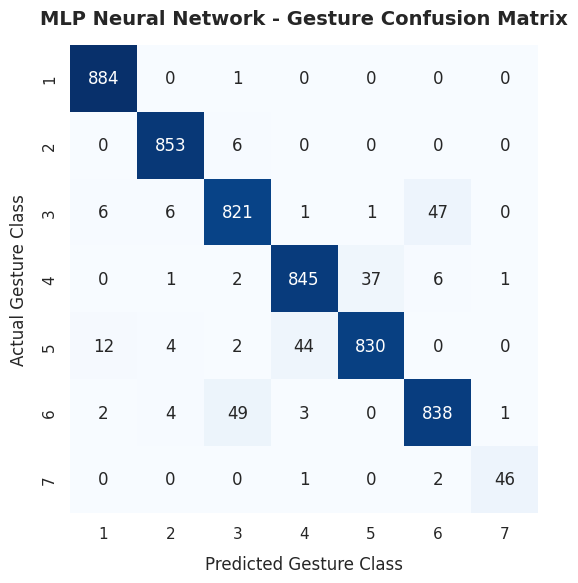

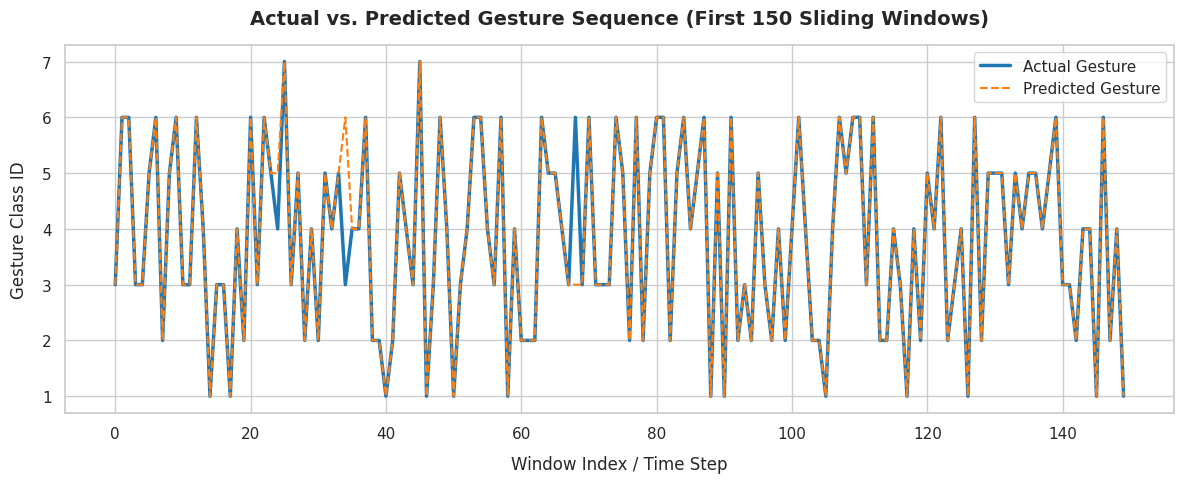

Graphs saved as 'confusion_matrix.png' and 'prediction_timeline.png'


In [36]:
# ==============================================================================
# CELL 7.7: CONFUSION MATRIX AND PREDICTION TIMELINE PLOTS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Set clean aesthetic for presentation/report figures
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

# ------------------------------------------------------------------------------
# 1. Plot Confusion Matrix
# ------------------------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred_mlp, labels=model_mlp.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_mlp.classes_,
    yticklabels=model_mlp.classes_,
    cbar=False,
    square=True
)

plt.title("MLP Neural Network - Gesture Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Predicted Gesture Class", fontsize=12, labelpad=10)
plt.ylabel("Actual Gesture Class", fontsize=12, labelpad=10)

plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 2. Plot Actual vs. Predicted Gesture Sequence (First 150 Test Samples)
# ------------------------------------------------------------------------------
num_samples = min(150, len(y_test))

plt.figure(figsize=(12, 5))
plt.plot(y_test[:num_samples], label="Actual Gesture", color="#1f77b4", linewidth=2.5, linestyle='-')
plt.plot(y_pred_mlp[:num_samples], label="Predicted Gesture", color="#ff7f0e", linewidth=1.5, linestyle='--')

plt.title(f"Actual vs. Predicted Gesture Sequence (First {num_samples} Sliding Windows)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Window Index / Time Step", fontsize=12, labelpad=10)
plt.ylabel("Gesture Class ID", fontsize=12, labelpad=10)
plt.yticks(model_mlp.classes_)
plt.legend(loc="upper right", frameon=True)

plt.savefig("prediction_timeline.png", dpi=300)
plt.show()

print("Graphs saved as 'confusion_matrix.png' and 'prediction_timeline.png'")

Tracking epoch-wise accuracy and loss...


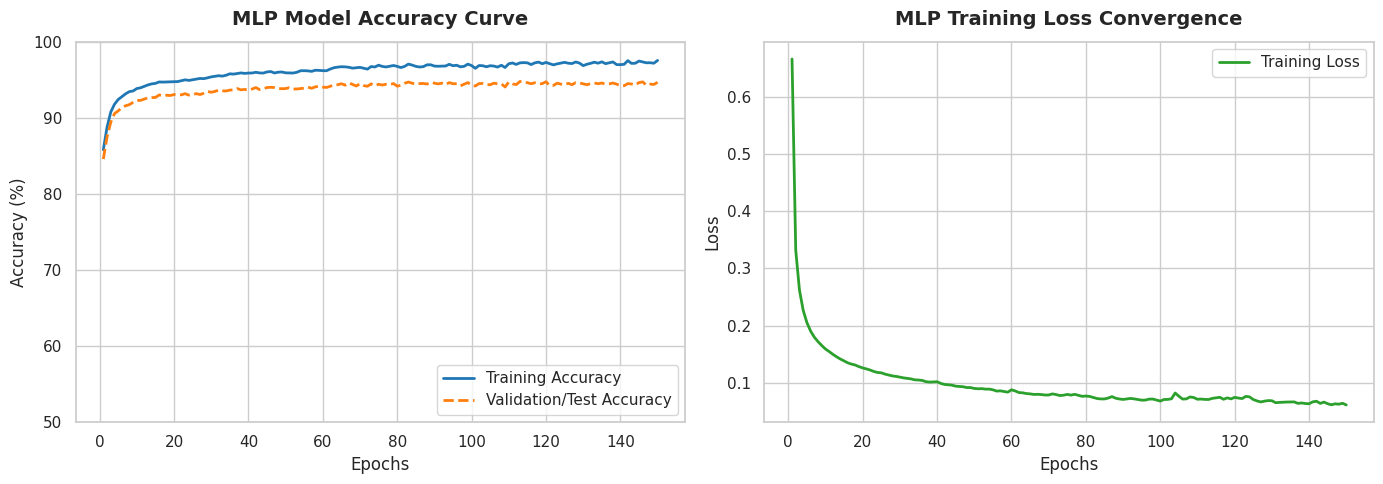

Graph saved as 'accuracy_loss_curves.png'


In [39]:
# ==============================================================================
# CELL 7.8: EPOCH-WISE LOSS AND ACCURACY PREDICTION GRAPH
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

# 1. Setup iterative model for epoch-wise evaluation
epochs = 150
train_acc_history = []
val_acc_history = []
loss_history = []

mlp_curve = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.005,
    random_state=42,
    warm_start=True
)

classes = np.unique(y_train)

print("Tracking epoch-wise accuracy and loss...")
for epoch in range(epochs):
    # Train for 1 epoch
    mlp_curve.partial_fit(X_train_scaled, y_train, classes=classes)

    # Store metrics
    loss_history.append(mlp_curve.loss_)
    train_acc_history.append(accuracy_score(y_train, mlp_curve.predict(X_train_scaled)) * 100)
    val_acc_history.append(accuracy_score(y_test, mlp_curve.predict(X_test_scaled)) * 100)

# ------------------------------------------------------------------------------
# 2. Plot Accuracy & Loss Prediction Curves
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Curve
ax1.plot(range(1, epochs + 1), train_acc_history, label='Training Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(range(1, epochs + 1), val_acc_history, label='Validation/Test Accuracy', color='#ff7f0e', linewidth=2, linestyle='--')
ax1.set_title('MLP Model Accuracy Curve', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.set_ylim([50, 100])
ax1.legend(loc='lower right', frameon=True)

# Loss Curve
ax2.plot(range(1, epochs + 1), loss_history, label='Training Loss', color='#2ca02c', linewidth=2)
ax2.set_title('MLP Training Loss Convergence', fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(loc='upper right', frameon=True)

plt.savefig('accuracy_loss_curves.png', dpi=300)
plt.show()

print("Graph saved as 'accuracy_loss_curves.png'")

In [37]:
# ==============================================================================
# CELL 8 & 9: SAVE & DOWNLOAD ALL REQUIRED FILES
# ==============================================================================
from google.colab import files

# Save model files locally
joblib.dump(model_mlp, 'emg_mlp_model.pkl')
joblib.dump(scaler, 'emg_scaler.pkl')
np.save('emg_classes.npy', model_mlp.classes_)

print("Triggering downloads for all files...")

# Download files
files.download('MLPModel.h')
files.download('emg_mlp_model.pkl')
files.download('emg_scaler.pkl')
files.download('emg_classes.npy')

Triggering downloads for all files...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
# ==============================================================================
# CELL 9: AUTOMATIC DOWNLOAD FOR PLOTS, CSVs, AND MODEL ARTIFACTS
# ==============================================================================
import os
import glob
from google.colab import files

print("Preparing downloads...\n")

# 1. Download Plot Images
if os.path.exists('confusion_matrix.png'):
    files.download('confusion_matrix.png')
if os.path.exists('prediction_timeline.png'):
    files.download('prediction_timeline.png')

# 2. Download Model & Header Artifacts
if os.path.exists('MLPModel.h'):
    files.download('MLPModel.h')
if os.path.exists('emg_mlp_model.pkl'):
    files.download('emg_mlp_model.pkl')
if os.path.exists('emg_scaler.pkl'):
    files.download('emg_scaler.pkl')
if os.path.exists('emg_classes.npy'):
    files.download('emg_classes.npy')

# 3. Search and Download CSV files (both generated and extracted CSVs)
csv_files = glob.glob('*.csv') + glob.glob('**/*.csv', recursive=True)
if csv_files:
    for csv_path in csv_files[:10]:  # Limits download queue to first 10 CSVs
        files.download(csv_path)
else:
    print("No CSV files found in the current working directory.")

print("All downloads triggered! Check your browser's download folder.")

Preparing downloads...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All downloads triggered! Check your browser's download folder.


In [40]:
# ==============================================================================
# EXPORT DATA FOR ORIGINPRO PLOTTING
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Export Accuracy & Loss Curve Data
df_acc_loss = pd.DataFrame({
    'Epoch': range(1, len(train_acc_history) + 1),
    'Training_Accuracy': train_acc_history,
    'Validation_Accuracy': val_acc_history,
    'Training_Loss': loss_history
})
df_acc_loss.to_csv('origin_accuracy_loss.csv', index=False)

# 2. Export Prediction Timeline Data
num_samples = min(150, len(y_test))
df_timeline = pd.DataFrame({
    'Window_Index': range(1, num_samples + 1),
    'Actual_Gesture': y_test[:num_samples],
    'Predicted_Gesture': y_pred_mlp[:num_samples]
})
df_timeline.to_csv('origin_prediction_timeline.csv', index=False)

# 3. Export Confusion Matrix Data (Matrix format for Heatmap)
df_cm = pd.DataFrame(cm, index=model_mlp.classes_, columns=model_mlp.classes_)
df_cm.to_csv('origin_confusion_matrix.csv')

print("Exported CSV files for OriginPro:")
print(" - origin_accuracy_loss.csv")
print(" - origin_prediction_timeline.csv")
print(" - origin_confusion_matrix.csv")

Exported CSV files for OriginPro:
 - origin_accuracy_loss.csv
 - origin_prediction_timeline.csv
 - origin_confusion_matrix.csv


In [41]:
from google.colab import files

print("Downloading OriginPro CSV files...")

# Trigger downloads directly in your browser
files.download('origin_accuracy_loss.csv')
files.download('origin_prediction_timeline.csv')
files.download('origin_confusion_matrix.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>